# TIB P4e: MiniCheck faithfulness of Pilot40 outputs (S/M/L views)

Scores the Pilot40 outputs (40 records x 5 profiles) with MiniCheck, one sentence at a time against the
source, and derives the faithfulness of the 60/120/240-word views from those sentence scores. Descriptive
only: no ranking, no selection. Scope and metric are fixed in `pilot_faithfulness_protocol.json`
(hash-checked first).

**Choose a T4 GPU runtime.** Inputs (private; TIB source use is local/private/noncommercial), in Drive
`MyDrive/TIB_P4E_261022/` on Colab: the code bundle zip and the Pilot40 evidence zip
(`tib-pilot40-evidence-*.zip`, exported by the Pilot40 notebook). Every record is checkpointed to Drive, so
a disconnected session can be resumed by running the notebook again. Failed or missing records are listed
and never scored as zero. First run of this scope: 191 records in 34 minutes on a T4.

**Rerun with sentence detail.** Metric, views and protocol are unchanged. This version also writes every
summary sentence with its MiniCheck probability to `PRIVATE_pilot_sentence_scores.jsonl` so flagged
sentences can be read against the source. That file holds text derived from the private sources: keep it
in the private Drive folder and on the local machine, never in the receipt, the code zip or the repository.
It uses new checkpoint, receipt and PNG names so the first run's files are not overwritten, and it
compares the new view scores with the first run's receipt as a reproducibility check.

In [1]:
import hashlib, json, platform, subprocess, sys, time, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/TIB_P4E_261022")  # private folder with the two input files
    ROOT = Path("/content/p4e"); ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(DRIVE_DIR / "tib-p4e-code-261022-v1.zip") as bundle:
        bundle.extractall(ROOT)
    RECORDS_PATH = DRIVE_DIR / "canonical_records.jsonl.gz"
    OUT_DIR = DRIVE_DIR / "results"
else:
    here = Path.cwd()
    ROOT = next(p for p in [here, *here.parents] if (p / "experiments/scripts/tib_faithfulness_cost.py").exists())
    RECORDS_PATH = ROOT / "research-data/tib-qualification-261019-1703/eda/canonical_records.jsonl.gz"
    OUT_DIR = ROOT / "experiments/outputs/tib-p4e-261022"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))
assert RECORDS_PATH.exists(), f"Missing input: {RECORDS_PATH}"

CRITERIA = ROOT / "experiments/registry/protocols/tib-reference-free-multilength-261022-v1/pilot_faithfulness_protocol.json"
EXPECTED_CRITERIA_SHA256 = "53410b2bf1cb543fcb48ae71a95057360f483f0f8c7e1ef77b19d25e4fd56b21"
actual = hashlib.sha256(CRITERIA.read_bytes()).hexdigest()
assert actual == EXPECTED_CRITERIA_SHA256, (
    f"Criteria file hash {actual} differs from the notebook's {EXPECTED_CRITERIA_SHA256}. "
    "Usually the code zip in Drive is an older build: upload the latest tib-p4e-code-261022-v1.zip, "
    "replace the old one, then Runtime > Restart session and run again. Do not edit the criteria file.")
print("root:", ROOT)
print("records:", RECORDS_PATH)
print("criteria sha256 verified:", actual[:16], "...")

Mounted at /content/drive
root: /content/p4e
records: /content/drive/MyDrive/TIB_P4E_261022/canonical_records.jsonl.gz
criteria sha256 verified: 53410b2bf1cb543f ...


In [2]:
import importlib.metadata as md_
def version(name):
    try:
        return md_.version(name)
    except md_.PackageNotFoundError:
        return None
ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(),
    "packages": {n: version(n) for n in ["nltk", "scikit-learn", "scipy", "numpy", "pandas", "torch", "transformers"]},
    "code_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in sorted((ROOT / "experiments/scripts").glob("tib_*.py"))},
}
print(json.dumps(ENVIRONMENT["packages"], indent=1))

{
 "nltk": "3.9.1",
 "scikit-learn": "1.6.1",
 "scipy": "1.16.3",
 "numpy": "2.1.3",
 "pandas": "2.2.3",
 "torch": "2.11.0+cu130",
 "transformers": "5.20.1"
}


In [3]:
import torch
assert torch.cuda.is_available(), "Select a GPU runtime (T4)"
ENVIRONMENT["gpu"] = torch.cuda.get_device_name(0)
print(ENVIRONMENT["gpu"], torch.__version__)

Tesla T4 2.11.0+cu130


## Install MiniCheck

In [4]:
INSTALL_LOG = {}
def pip(label, *args):
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], capture_output=True, text=True)
    INSTALL_LOG[label] = {"returncode": result.returncode, "tail": (result.stderr or result.stdout)[-400:]}
    print(label, "ok" if result.returncode == 0 else "FAILED")
    if result.returncode:
        print("   ", INSTALL_LOG[label]["tail"])
pip("MiniCheck", "minicheck @ git+https://github.com/Liyan06/MiniCheck.git@main")
import nltk  # recent NLTK needs punkt_tab, which MiniCheck does not download
for resource in ("punkt", "punkt_tab"):
    nltk.download(resource, quiet=True)

MiniCheck ok


## Load the Pilot40 outputs

In [5]:
from experiments.scripts import tib_pilot_faithfulness as pf
if IN_COLAB:
    candidates = sorted(DRIVE_DIR.glob("tib-pilot40-evidence-*.zip"))
else:
    candidates = sorted((ROOT / "experiments/outputs").rglob("tib-pilot40-evidence-*.zip"))
assert candidates, "Put the Pilot40 evidence zip (tib-pilot40-evidence-*.zip) in the input folder"
EVIDENCE_ZIP = candidates[-1]
print("evidence:", EVIDENCE_ZIP.name, hashlib.sha256(EVIDENCE_ZIP.read_bytes()).hexdigest()[:16])
ROWS, SKIPPED = pf.collect_rows(EVIDENCE_ZIP)
from collections import Counter
print("to score:", dict(Counter(r["candidate"] for r in ROWS)))
print("not scored:", dict(Counter((s["candidate"], s["status"]) for s in SKIPPED)))
assert ROWS, "No usable outputs in the evidence zip"

evidence: tib-pilot40-evidence-20261023T074252Z.zip 39cc411bd3304041
to score: {'bart': 37, 'lead3': 40, 'led': 37, 'lexrank': 40, 'qwen3': 37}
not scored: {('bart', 'failed'): 3, ('led', 'failed'): 3, ('qwen3', 'failed'): 3}


## Score (checkpointed; run again to resume)

In [6]:
score_claims, MINICHECK_INFO = pf.load_minicheck_claims()
# New names: the checkpoint of the first run holds no sentence detail, so it must not be resumed.
CHECKPOINT = OUT_DIR / "pilot_faithfulness_scores_sentences.jsonl"
DETAIL_PATH = OUT_DIR / "PRIVATE_pilot_sentence_scores.jsonl"  # sentence text: keep private
started = time.monotonic()
done = {"n": 0}
def progress(scored):
    done["n"] += 1
    if done["n"] % 10 == 0:
        print(done["n"], "new rows,", round((time.monotonic() - started) / 60, 1), "min")
RESULTS = pf.score_rows(ROWS, score_claims, CHECKPOINT, on_row=progress, detail_path=DETAIL_PATH)
SCORING_SECONDS = time.monotonic() - started
print("rows:", len(RESULTS), "errors:", sum(1 for r in RESULTS if "views" not in r),
      "new-scoring minutes this run:", round(SCORING_SECONDS / 60, 1))
errors = [r for r in RESULTS if "views" not in r]
if errors:
    print("first error:", errors[0].get("error"))
# A record that was scored but crashed before its checkpoint line appears twice in the detail file; keep the last.
detail_records = {}
for line in DETAIL_PATH.read_text(encoding="utf-8").splitlines():
    item = json.loads(line)
    detail_records[(item["candidate"], item["record_id"])] = item
print("records with sentence detail:", len(detail_records), "of", sum(1 for r in RESULTS if "views" in r))

config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/75.0 [00:00<?, ?B/s]

... (42 outputs left out)

Evaluating: 100%|██████████| 9/9 [00:24<00:00,  2.73s/it]


190 new rows, 40.2 min


Evaluating: 100%|██████████| 10/10 [00:20<00:00,  2.03s/it]

rows: 191 errors: 0 new-scoring minutes this run: 40.5
records with sentence detail: 191 of 191


## Reproducibility against the first run

In [7]:
FIRST_RECEIPT = OUT_DIR / "pilot_faithfulness_receipt.json"
if FIRST_RECEIPT.exists():
    DRIFT = pf.max_abs_view_diff(RESULTS, json.loads(FIRST_RECEIPT.read_text(encoding="utf-8"))["scores"])
    print(DRIFT)
else:
    DRIFT = None
    print("first-run receipt not found; no comparison")

{'compared_views': 573, 'max_abs_diff': 0.0, 'missing_in_previous': []}


## Summary (descriptive, no ranking)

In [8]:
import pandas as pd
TABLE = pf.summarize(RESULTS, SKIPPED)
flat = [{"candidate": c, "scored": e["scored_records"], "errors": e["error_records"],
         "not_scored": e["not_scored_records"],
         **{f"{v}_prob": e["views"][v]["mean_prob"] for v in pf.VIEW_NAMES},
         **{f"{v}_flagged": e["views"][v]["flagged_share"] for v in pf.VIEW_NAMES}}
        for c, e in TABLE.items()]
pd.set_option("display.width", 200)
print(pd.DataFrame(flat).round(3).to_string(index=False))
receipt = {
    "schema_version": 1, "protocol_id": "tib-pilot40-faithfulness-minicheck-v1",
    "protocol_sha256": EXPECTED_CRITERIA_SHA256,
    "evidence_zip": EVIDENCE_ZIP.name, "evidence_zip_sha256": hashlib.sha256(EVIDENCE_ZIP.read_bytes()).hexdigest(),
    "environment": ENVIRONMENT, "install_log": INSTALL_LOG, "minicheck": MINICHECK_INFO,
    "scoring_seconds_this_run": SCORING_SECONDS, "table": TABLE,
    "skipped": SKIPPED, "scores": RESULTS, "drift_against_first_run": DRIFT,
    "sentence_detail_file": DETAIL_PATH.name,
}
path = OUT_DIR / "pilot_faithfulness_receipt_sentences.json"
path.write_text(json.dumps(receipt, indent=2), encoding="utf-8")
print(path, hashlib.sha256(path.read_bytes()).hexdigest()[:16])

candidate  scored  errors  not_scored  S_prob  M_prob  L_prob  S_flagged  M_flagged  L_flagged
     bart      37       0           3   0.852   0.852   0.852      0.148      0.148      0.148
    lead3      40       0           0   0.936   0.936   0.936      0.025      0.025      0.025
      led      37       0           3   0.766   0.766   0.773      0.185      0.195      0.195
  lexrank      40       0           0   0.969   0.966   0.970      0.000      0.007      0.007
    qwen3      37       0           3   0.495   0.476   0.475      0.511      0.524      0.533
/content/drive/MyDrive/TIB_P4E_261022/results/pilot_faithfulness_receipt_sentences.json 1f87319e11072506


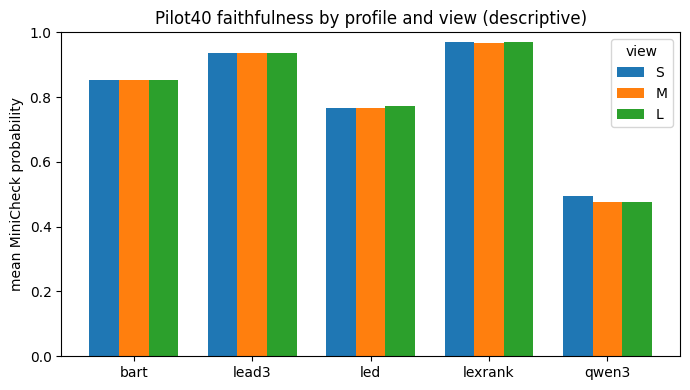

In [9]:
import matplotlib.pyplot as plt
names = [c for c, e in TABLE.items() if e["scored_records"]]
fig, ax = plt.subplots(figsize=(7, 4))
width = 0.25
for j, view in enumerate(pf.VIEW_NAMES):
    ax.bar([i + (j - 1) * width for i in range(len(names))],
           [TABLE[n]["views"][view]["mean_prob"] for n in names], width, label=view)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
ax.set_ylabel("mean MiniCheck probability"); ax.set_ylim(0, 1); ax.legend(title="view")
ax.set_title("Pilot40 faithfulness by profile and view (descriptive)")
fig.tight_layout(); fig.savefig(OUT_DIR / "pilot_faithfulness_sentences.png", dpi=130); plt.show()

## What to keep
`pilot_faithfulness_receipt_sentences.json` (view scores and the drift check; no sentence text) and the PNG
may be shared. `PRIVATE_pilot_sentence_scores.jsonl` holds the sentences themselves: download it to the
local machine only. The pilot is 40 records per profile and one realization: read the table as a
description of this pipeline's outputs, not as a ranking of the profiles.